In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft
from matplotlib.animation import FuncAnimation, PillowWriter
import fhd
import importlib
import time
from scipy.stats import linregress


importlib.reload(fhd)

<module 'fhd' from '/home/wmrs@cbsp.nl/codebase/fluctuating_hydro/fhd/__init__.py'>

In [2]:
N = (2**7, 2**7)
L = (50,50)
Lx, Ly = L
sim_2d = fhd.fhd_2d(L,N, bc= 'periodic', fft=False)



In [3]:
#LOAD SWEEP CODE:
# averaging_bp = -200
N = (2**7, 2**7)
L = (50,50)
Lx, Ly = L
sim_2d = fhd.fhd_2d(L,N, bc= 'periodic', fft=False)

# Ta = 2/5
# Tb = 2/5
# kappa_aa = 1-Ta
# kappa_bb = 1-Tb
# kappa_ab = -Ta
# kappa_ba = -Tb
nu = np.zeros((2,2,2))
# # coupling matrix kappa  for pi^{(a)} = sum_b kappa_ab * (V * phi_b)
# kappa = np.array([[kappa_aa, kappa_ab],
#                   [kappa_ba, kappa_bb]])
D = 0.1*np.ones(2) # Schelling diffusion coefficient
Gamma = np.eye(2) # Utility nabla^3 term coefficient
D_v = 0.1 #Voter model diffusion term
beta = 10

x = sim_2d.x
y = sim_2d.y

xx, yy = np.meshgrid(x, y, indexing='ij')
nspecies = sim_2d.nspecies
num_bins = 60

Dv_space = np.array([0.001, 0.02])

regimes = ["segregating"] #, "integrating"] #, "migrating", "well-mixed"]
kappas = [np.array([[0.6, -0.4],[-0.4, 0.6]]), np.array([[0.6, 1], [1, 0.6]]),
np.array([[1, 1], [-1, 1]]), np.array([[0.6, 0.4], [0.6, 0.4]])]

param = {'D': D, 'kappa': kappas[0], 'Gamma': Gamma, 'nu': nu, 'D_v': D_v, 'beta': beta, 'noise_v' : 1, 'h': 0.1}

kmeans = np.zeros((len(regimes), len(Dv_space),2001))
# kpeaks = np.zeros(4)

dt = 0.002
nsteps = 2000000
noise = True
frames = 2000

def kmean(power_spectrum, k_bins):
    Z = np.sum(power_spectrum)
    kmean = np.sum(k_bins*power_spectrum)
    return kmean/Z

for r, regime in enumerate(regimes):
    for id, D_v in enumerate(Dv_space):
        phi_runs = []
        k_runs = []
        for n_run in range(10):
            try:    
                phi_run = np.load(f"data/time_scaling2/{regime}_run_{n_run}_fluc_Dv{D_v:.3f}.npy")
                phi_runs.append(phi_run)
                length_run = phi_run.shape[1]
                k_run = []
                for i in range(length_run):
                    k_bins, power_spectra, G_AB =  fhd.power_spectrum(phi_run[:,i:i+1], (Lx, Ly), num_bins=60, averaged = False,  centered = True)
                    k_run.append(kmean(power_spectra[0]+power_spectra[1],k_bins))
                k_runs.append(k_run)
            except:
                print(f"Failed to load {regime} sweep run {n_run} for Dv = {D_v:.2f}")
                
        kmeans[r,id] = pd.DataFrame(k_runs).mean().values

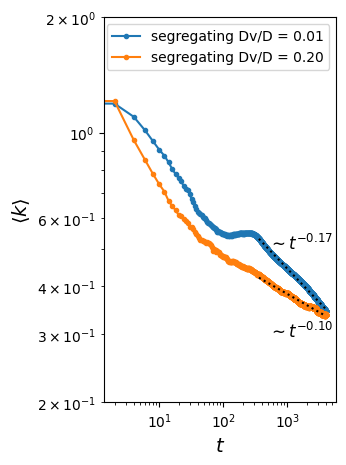

In [47]:
dt = 0.002
nsteps = 2000000
noise = True
frames = 2000

plt.figure(figsize=(3,5))

t = np.linspace(0, dt*nsteps, frames+1)
for r, reg in enumerate(regimes):
    for i, Dv in enumerate(Dv_space):
        plt.loglog(t, kmeans[r,i], '.-', label = reg+f" Dv/D = {Dv/D[0]:.2f}")
        
        fit_s = 180
        fit_e = 2000
        x = np.log(t[fit_s:fit_e])
        y = np.log(kmeans[r,i,fit_s:fit_e])

        res = linregress(x,y)

        slope = res.slope
        a = np.exp(res.intercept)
        plt.text(
            500, 0.55-i*(1-0.1)/4,
            rf"$\sim t^{{{slope:.2f}}}$",
            fontsize=12,
            va="top",
            ha="left"
        )
        plt.plot(t[fit_s:fit_e], a*t[fit_s:fit_e]**slope, ":k")
# plt.loglog(t, 1.2*t**(-1/3), label= 't^(-1/3)')
# plt.loglog(t, 1.2*t**(-1/4), label= 't^(-1/4)')
plt.legend()
plt.ylabel(r"$\langle k \rangle$", size=14)
plt.xlabel(r"$t$", size=14)
plt.ylim([0.2,2])
plt.show()

In [ ]:
slope

np.float64(-0.20781908655266196)

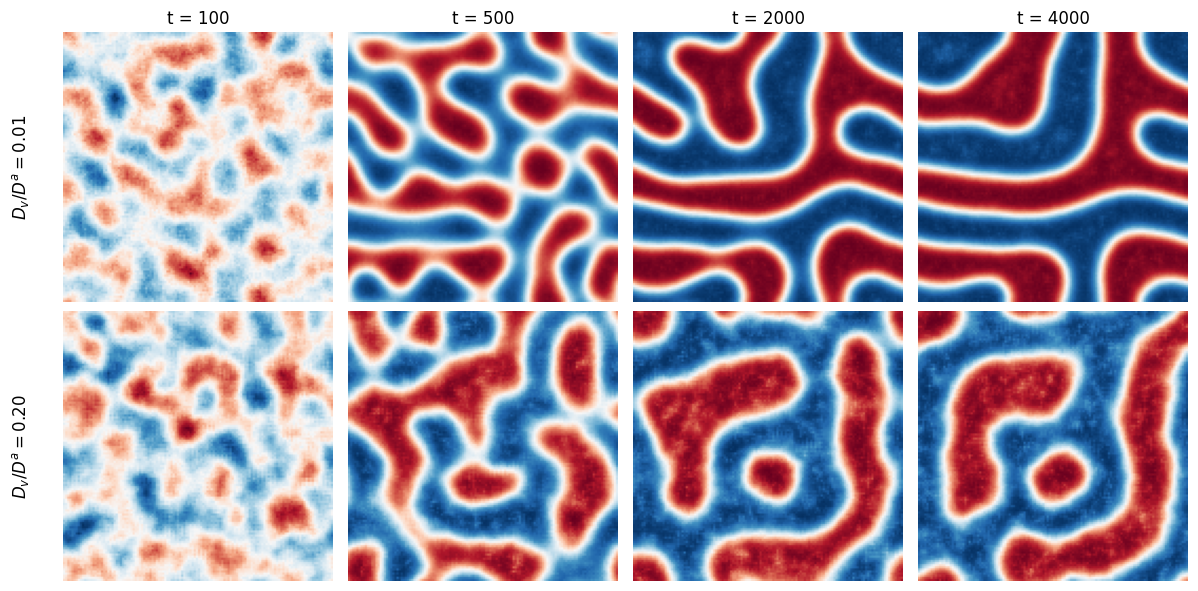

In [46]:
n_run = 2
times = [50, 250, 1000, 2000]
time_label = [int(dt*t*nsteps/frames) for t in times]

fig, axs = plt.subplots(2, 4, figsize=(12, 6))

for i, D_v in enumerate(Dv_space):
    phi_run = np.load(
        f"data/time_scaling2/{regime}_run_{n_run}_fluc_Dv{D_v:.3f}.npy"
    )
    phi_diff = phi_run[0] - phi_run[1]

    for j, ti in enumerate(times):
        axs[i, j].imshow(phi_diff[ti], cmap="RdBu")
        axs[i, j].axis("off")

        # Column labels: time
        if i == 0:
            axs[i, j].set_title(f"t = {time_label[j]}", fontsize=12)

    # Row labels: D_v
    axs[i, 0].text(
        -0.12, 0.5,
        rf"$D_v/D^a = {D_v/D[0]:.2f}$",
        transform=axs[i, 0].transAxes,
        ha="right",
        va="center",
        rotation=90,
        fontsize=12,
    )

# Solid black line between the two rows
# line = plt.Line2D(
#     [0.08, 0.98], [0.5, 0.5],
#     transform=fig.transFigure,
#     color="black",
#     linewidth=2,
# )
# fig.add_artist(line)

plt.tight_layout()
plt.show()


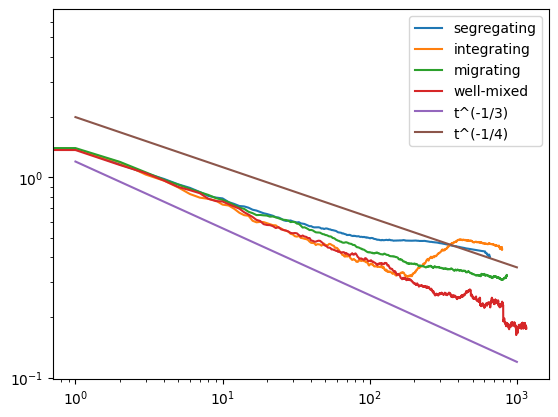

In [25]:
t = np.logspace( 0,3, 1000)
for r, reg in enumerate(regimes):
    plt.loglog(kmeans[r], label = reg)
plt.loglog(t, 1.2*t**(-1/3), label= 't^(-1/3)')
plt.loglog(t, 2*t**(-1/4), label= 't^(-1/4)')
plt.legend()